# 1- Import libraries

# 2- Import dataset

In [1]:
import pandas as pd

df = pd.read_csv("C:/Users/engza/OneDrive/Desktop/Project2/Data/Original/reviews.csv")
df.head()

,Review,Attribute,Result
0,الاكل كان مناسب والسانويش كان لذيذ,المأكولات,ايجابي
1,منيو الطعام سيء,المأكولات,سلبي
2,المأكولات من سندويش وحلا كان طيب عموما الاكل طيب,المأكولات,ايجابي
3,افضل دونات تبدا فيها يومك,المأكولات,ايجابي
4,خيار ممتاز للقهوه,المشروبات,ايجابي


In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

relative_path = Path("Data/Original/reviews.csv")
source = next(
    (root / relative_path for root in (Path.cwd(), *Path.cwd().parents)
     if (root / relative_path).is_file()),
    None,
)
if source is None:
    raise FileNotFoundError(relative_path)

encoding = "utf-8-sig"  # Use the encoding that works for your source file
df = pd.read_csv(source, encoding=encoding)
columns = ["Review", "Attribute", "Result"]
if not set(columns).issubset(df.columns):
    df = pd.read_csv(source, encoding=encoding, sep=";")
if not set(columns).issubset(df.columns):
    raise ValueError(f"Expected {columns}, found {df.columns.tolist()}")

# 3- Exploratory data analysis

## 1. initial analysis ( Strucrue , shape,number of records)

In [3]:
# view dimensions of dataset

df.shape
df

,Review,Attribute,Result
0,الاكل كان مناسب والسانويش كان لذيذ,المأكولات,ايجابي
1,منيو الطعام سيء,المأكولات,سلبي
2,المأكولات من سندويش وحلا كان طيب عموما الاكل طيب,المأكولات,ايجابي
3,افضل دونات تبدا فيها يومك,المأكولات,ايجابي
4,خيار ممتاز للقهوه,المشروبات,ايجابي
...,...,...,...
2995,خدمه جدا سيئة لا يوجد مشرف ولا احد ينضم الكاشي...,الخدمة,سلبي
2996,خذيت طلب ه ب٧ ريال سعرها مناسب,الاسعار,ايجابي
2997,جربت سجننشر بارد حبيتتت طعمه,المشروبات,ايجابي
2998,هاف مليون ولا اروع بصراحه قهوه وكل المشروبات ا...,المشروبات,ايجابي


In [4]:
df.head()

,Review,Attribute,Result
0,الاكل كان مناسب والسانويش كان لذيذ,المأكولات,ايجابي
1,منيو الطعام سيء,المأكولات,سلبي
2,المأكولات من سندويش وحلا كان طيب عموما الاكل طيب,المأكولات,ايجابي
3,افضل دونات تبدا فيها يومك,المأكولات,ايجابي
4,خيار ممتاز للقهوه,المشروبات,ايجابي


In [5]:
df.tail()

,Review,Attribute,Result
2995,خدمه جدا سيئة لا يوجد مشرف ولا احد ينضم الكاشي...,الخدمة,سلبي
2996,خذيت طلب ه ب٧ ريال سعرها مناسب,الاسعار,ايجابي
2997,جربت سجننشر بارد حبيتتت طعمه,المشروبات,ايجابي
2998,هاف مليون ولا اروع بصراحه قهوه وكل المشروبات ا...,المشروبات,ايجابي
2999,وجربت بيقل حلوم طعمها رووعه,المأكولات,ايجابي


In [6]:
df.describe() # describe() gives quick statistics (mean, min, max...) for the numeric columns


,Review,Attribute,Result
count,3000,3000,3000
unique,2808,5,3
top,غالي الثمن\n\n\nExpensive;الاسعار;سلبي,المشروبات,ايجابي
freq,4,927,1862


In [7]:
df.info()   # info() shows each column, its data type, and how many values are NOT missing

<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   Review     3000 non-null   str  
 1   Attribute  3000 non-null   str  
 2   Result     3000 non-null   str  
dtypes: str(3)
memory usage: 405.8 KB


## 2. Check null values

In [8]:
missing_markers = {"", "non", "none", "null", "na", "n/a", "nan", "-"}
normalized = df.apply(lambda column: column.str.strip().str.lower())
missing_mask = df.isna() | normalized.isin(missing_markers)
display(missing_mask.sum().rename("Missing values"))


Review       0
Attribute    0
Result       0
Name: Missing values, dtype: int64

In [9]:
# Count and percentage of missing values per column
missing = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_pct": (df.isnull().mean() * 100).round(1),
})
print("--- COLUMNS WITH MISSING VALUES ---")
display(missing[missing["missing_count"] > 0].sort_values("missing_count", ascending=False))

--- COLUMNS WITH MISSING VALUES ---


,missing_count,missing_pct


In [10]:

display(df.isna().sum())



Review       0
Attribute    0
Result       0
dtype: int64

## 3. Check Duplicate values

In [11]:

# Count rows that are exact copies of an earlier row
print("\nDuplicate rows:", df.duplicated().sum())


Duplicate rows: 184


In [12]:
duplicates = df[df.duplicated(keep=False)]
display(duplicates.sort_values(["Review", "Attribute", "Result"]).head(10))

,Review,Attribute,Result
60,\n- بطء استلام الطلب لكن تسليمه سريع جدًا < ال...,الخدمة,سلبي
555,\n- بطء استلام الطلب لكن تسليمه سريع جدًا < ال...,الخدمة,سلبي
72,احب دائما عندهم مشروب وايت موكا. لاتيه حار....,المشروبات,ايجابي
909,احب دائما عندهم مشروب وايت موكا. لاتيه حار....,المشروبات,ايجابي
387,ولكن هناك منافسين له واسعارهم اقل منهم بكثير...,الاسعار,سلبي
1291,ولكن هناك منافسين له واسعارهم اقل منهم بكثير...,الاسعار,سلبي
32,أحب خدمة السيارات لديهم\n\n\nLove the drive t...,الخدمة,ايجابي
498,أحب خدمة السيارات لديهم\n\n\nLove the drive t...,الخدمة,ايجابي
229,أحبها الآن محطة القهوة الأكثر شعبية في المملك...,المشروبات,ايجابي
1154,أحبها الآن محطة القهوة الأكثر شعبية في المملك...,المشروبات,ايجابي


In [13]:
df_clean = df.drop_duplicates().reset_index(drop=True)

print("Shape after removing duplicates:", df_clean.shape)
print("Remaining duplicate rows:", df_clean.duplicated().sum())

Shape after removing duplicates: (2816, 3)
Remaining duplicate rows: 0


## 4.Check data types

In [14]:
display(df_clean.dtypes)

Review       str
Attribute    str
Result       str
dtype: object

In [15]:
pattern = (
    r"(?:;\s*(?:الخدمة|المشروبات|الجلسات|المأكولات|ال[اأ]سعار)"
    r"\s*;\s*(?:[اإ]يجابي|سلب[يى]|محايد)\s*)+$"
)
embedded = df_clean["Review"].str.contains(pattern, regex=True, na=False)
print("Reviews with embedded labels:", embedded.sum())

df_model = df_clean.copy()
df_model["Review"] = df_model["Review"].str.replace(pattern, "", regex=True).str.strip()
for column in ["Attribute", "Result"]:
    df_model[column] = df_model[column].str.strip()

blank = df_model["Review"].eq("")
print("Empty reviews after cleaning:", blank.sum())
print("Duplicate rows after cleaning:", df_model.loc[~blank].duplicated().sum())
df_model = df_model.loc[~blank].drop_duplicates().reset_index(drop=True)
assert not df_model["Review"].str.contains(pattern, regex=True, na=False).any()
print("Final shape:", df_model.shape)

Reviews with embedded labels: 465
Empty reviews after cleaning: 0
Duplicate rows after cleaning: 9
Final shape: (2807, 3)


In [16]:
pattern = (
    r"(?:;\s*(?:الخدمة|المشروبات|الجلسات|المأكولات|ال[اأ]سعار)"
    r"\s*;\s*(?:[اإ]يجابي|سلب[يى]|محايد)\s*)+$"
)
embedded = df_clean["Review"].str.contains(pattern, regex=True, na=False)
print("Reviews with embedded labels:", embedded.sum())

df_model = df_clean.copy()
df_model["Review"] = df_model["Review"].str.replace(pattern, "", regex=True).str.strip()
for column in ["Attribute", "Result"]:
    df_model[column] = df_model[column].str.strip()

blank = df_model["Review"].eq("")
print("Empty reviews after cleaning:", blank.sum())
print("Duplicate rows after cleaning:", df_model.loc[~blank].duplicated().sum())
df_model = df_model.loc[~blank].drop_duplicates().reset_index(drop=True)
assert not df_model["Review"].str.contains(pattern, regex=True, na=False).any()
print("Final shape:", df_model.shape)

Reviews with embedded labels: 465
Empty reviews after cleaning: 0
Duplicate rows after cleaning: 9
Final shape: (2807, 3)


In [17]:
repeated_reviews = df_model.loc[df_model["Review"].duplicated(keep=False)]
print("Rows with repeated review text:", len(repeated_reviews))
print("Distinct repeated texts:", repeated_reviews["Review"].nunique())
display(repeated_reviews.sort_values("Review").head(10))

Rows with repeated review text: 22
Distinct repeated texts: 11


,Review,Attribute,Result
2019,الموقع تمام و التعامل تمام وسرعة الطلب,الخدمة,ايجابي
2044,الموقع تمام و التعامل تمام وسرعة الطلب,الخدمة,سلبي
36,تجربة الله ليست سيئة خدمة متوسطة\n\n\nGud expe...,الخدمة,ايجابي
463,تجربة الله ليست سيئة خدمة متوسطة\n\n\nGud expe...,الخدمة,محايد
359,جميل ولكن لدي تحفظ من ناحية الأسعار,الاسعار,سلبي
372,جميل ولكن لدي تحفظ من ناحية الأسعار,الاسعار,محايد
410,جميل لكن كعادة استاربوكس هنا اسعاره غالي,الاسعار,محايد
1178,جميل لكن كعادة استاربوكس هنا اسعاره غالي,الاسعار,سلبي
494,جميل موقع يحتاج اهتمام بالنظافة اكثر في الطاب...,الجلسات,سلبي
549,جميل موقع يحتاج اهتمام بالنظافة اكثر في الطاب...,الخدمة,سلبي


## 5. Categorical Cardinality and Frequency

In [18]:
for col in ["Attribute", "Result"]:
    print(f"{col} — Cardinality: {df_clean[col].nunique()}")
    display(df_clean[col].value_counts())

Attribute — Cardinality: 5


Attribute
المشروبات    896
الخدمة       649
الجلسات      518
المأكولات    422
الاسعار      331
Name: count, dtype: int64

Result — Cardinality: 3


Result
ايجابي    1798
سلبي       755
محايد      263
Name: count, dtype: int64

## 5.Types of variables

In [19]:
# Split the columns by type
numeric_cols = df.select_dtypes(include="number").columns.tolist()
text_cols = df.select_dtypes(exclude=["number", "datetime"]).columns.tolist()
print(f"\nNumerical columns ({len(numeric_cols)}): {numeric_cols}")
print(f"Text columns ({len(text_cols)}): {text_cols}")


Numerical columns (0): []
Text columns (3): ['Review', 'Attribute', 'Result']


In [20]:
# find categorical variables

categorical = [var for var in df.columns if df[var].dtype=='O']  #Object

print('There are {} categorical variables\n'.format(len(categorical)))

print('The categorical variables are :', categorical)

There are 0 categorical variables

The categorical variables are : []


In [21]:
# check missing values in categorical variables

df[categorical].isnull().sum()

Series([], dtype: float64)

In [22]:
# check for cardinality in categorical variables

for var in categorical:

    print(var, ' contains ', len(df[var].unique()), ' labels')

## 2. EDA Visualizing

## Univariate Analysis

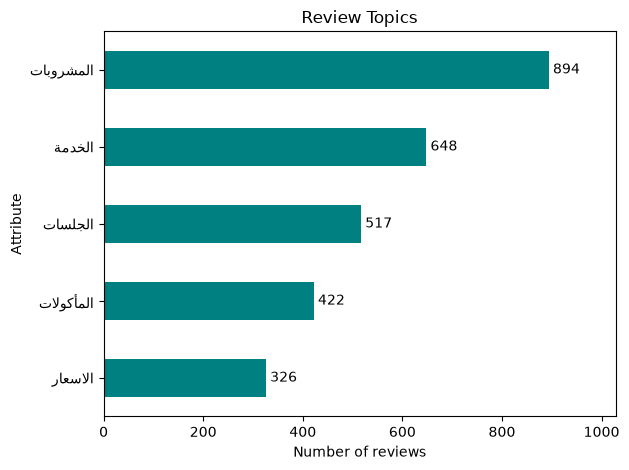

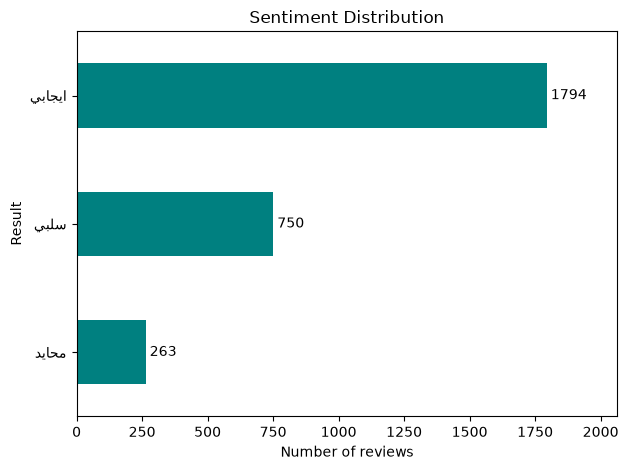

In [23]:
for column, title in [("Attribute", "Review Topics"), ("Result", "Sentiment Distribution")]:
    ax = df_model[column].value_counts().plot.barh(title=title, color="teal")
    ax.invert_yaxis()
    ax.bar_label(ax.containers[0], padding=3)
    ax.margins(x=0.15)
    ax.set_xlabel("Number of reviews")
    plt.tight_layout()
    plt.show()

## 2.Bivariate Analysis — Sentiment by Review Topic


Result,ايجابي,سلبي,محايد
Attribute,,,
الاسعار,139,152,35
الجلسات,365,106,46
الخدمة,274,302,72
المأكولات,316,58,48
المشروبات,700,132,62


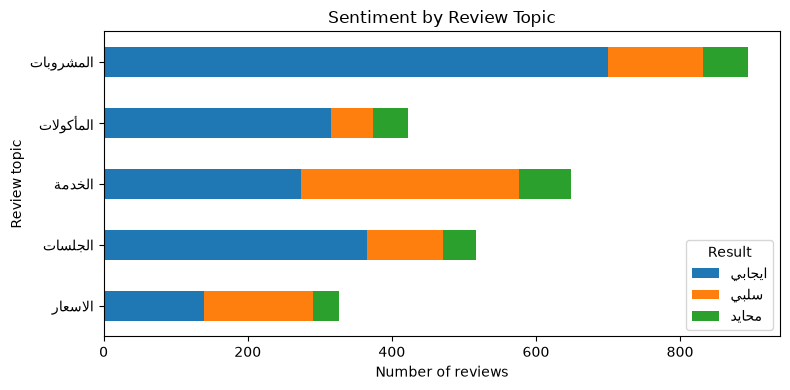

In [24]:
counts = pd.crosstab(df_model["Attribute"], df_model["Result"])
display(counts)
ax = counts.plot.barh(stacked=True, figsize=(8, 4))
ax.set(title="Sentiment by Review Topic", xlabel="Number of reviews", ylabel="Review topic")
plt.tight_layout()
plt.show()

Top Three Topics by Negative Review Count

In [25]:
negative_by_topic = pd.DataFrame({
    "Negative Reviews": counts.get("سلبي", pd.Series(0, index=counts.index)),
    "Total Reviews": counts.sum(axis=1),
})
negative_by_topic["Negative Rate (%)"] = (
    100 * negative_by_topic["Negative Reviews"] / negative_by_topic["Total Reviews"]
).round(1)
display(negative_by_topic.nlargest(3, "Negative Reviews"))

,Negative Reviews,Total Reviews,Negative Rate (%)
Attribute,,,
الخدمة,302,648,46.6
الاسعار,152,326,46.6
المشروبات,132,894,14.8


Explore Negative Service Reviews

In [26]:
service_negative = df_model.loc[
    df_model["Attribute"].eq("الخدمة") & df_model["Result"].eq("سلبي"), "Review"
]
sample = service_negative.sample(n=min(10, len(service_negative)), random_state=42)
for number, review in enumerate(sample, start=1):
    print(f"{number}. {review}\n")

1. من اسوء الفروع كخدمه وكعماله اسيويه فيه تعمل لا جوده نظافه معدات ولا تعامل لبق مع الزبائن حتى مشين  لا تتنظف بشكل جيد

2. كل م رحت ابي طلبي يقول قضاء

3. موقعه خطر ويسبب زحمه في الطريق

4. العامل المصري ما أدري غبي او يتغيبى او يطقطق على الزباين اقوله ابي

5. المكان والموقع خطير ولكن بعض الاحيان الموظفين الله يسامحهم مزاجهم مش ولابد ولكن المكان  وملاحظه اخيره هو 24 ساعه ولكن زرته اكثر من مره ومقفل للاسف

6. المصيبه في دورة المياه قذره وكلمت العامل اذا في احد ينظفه قال لا ما فيه

7. لكن للاسف العمال باردين او ما عندهم احساس مسؤولية
اربع عمال و السرا واصل للباب !!!
و المشكلة اثنين يسولفون على مكينة القهوة ..!!

8. بصراحه ما عندي فكره عن التدهور الي حل بدانكن دونتس ، في الأونه الأخيره

9. فرع نايم لجافا  عمالة تسليك شغلهم يفرق عن الفروع الاخرء سيء جدا

10. سبق و علقت و اشكر الموظفين ع تعاونهم

. لكن الشيء الغريب اشتريت منهم كوب للمشروبات البارده هذا قبل فترة .. لكن طلبت اليوم  مشروب بارد و تفاجأت انو يقول ممنوع نعبيه لك يعني نعطيك كوب بلاستيك و نت الله لايهينك تصبه بالكوب اللي شريته من

Export Cleaned Reviews

In [27]:
output_path = source.parents[1] / "Cleaned" / "reviews_cleaned.csv"
output_path.parent.mkdir(parents=True, exist_ok=True)
df_model.to_csv(output_path, index=False, encoding="utf-8-sig")
print("Saved:", output_path)

Saved: c:\Users\engza\OneDrive\Desktop\Project2\Data\Cleaned\reviews_cleaned.csv


## 1. Distribution of Result(Target)

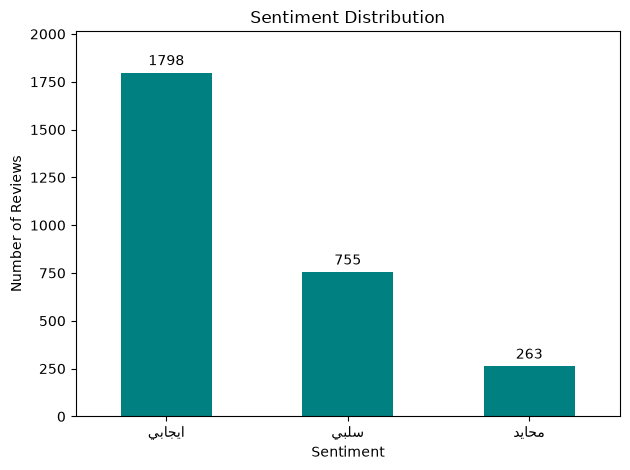

In [28]:
import matplotlib.pyplot as plt

result_counts = df_clean["Result"].value_counts()

ax = result_counts.plot(kind="bar", color="teal", rot=0)
ax.bar_label(ax.containers[0], padding=3)
ax.margins(y=0.12)
ax.set(
    title="Sentiment Distribution",
    xlabel="Sentiment",
    ylabel="Number of Reviews",
)
plt.tight_layout()
plt.show()

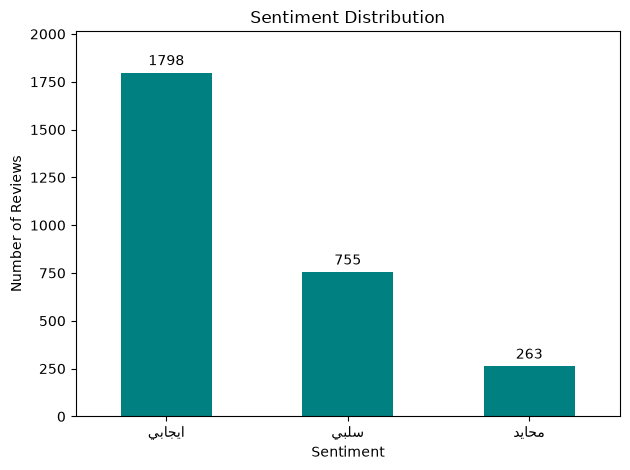

In [29]:
import matplotlib.pyplot as plt

result_counts = df_clean["Result"].value_counts()

ax = result_counts.plot(kind="bar", color="teal", rot=0)
ax.bar_label(ax.containers[0], padding=3)
ax.margins(y=0.12)
ax.set(
    title="Sentiment Distribution",
    xlabel="Sentiment",
    ylabel="Number of Reviews",
)
plt.tight_layout()
plt.show()

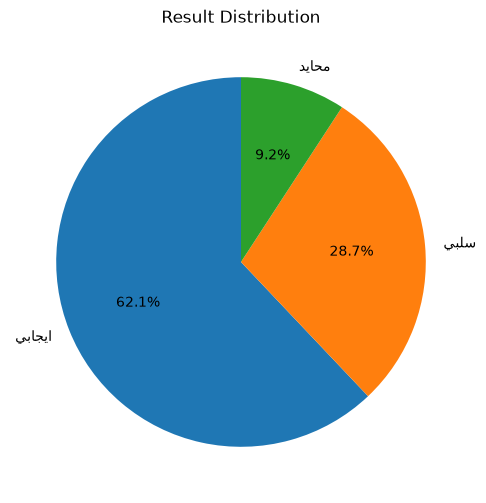

In [30]:
import matplotlib.pyplot as plt

result_counts = df["Result"].value_counts()

fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(
    result_counts.values,
    labels=result_counts.index,
    autopct="%1.1f%%",
    startangle=90,
)
ax.set_title("Result Distribution")
plt.show()

## Bivariate Analysis

## 1. Sentiment by Review Topic

Result,ايجابي,سلبي,محايد
Attribute,,,
الاسعار,139,157,35
الجلسات,366,106,46
الخدمة,275,302,72
المأكولات,316,58,48
المشروبات,702,132,62


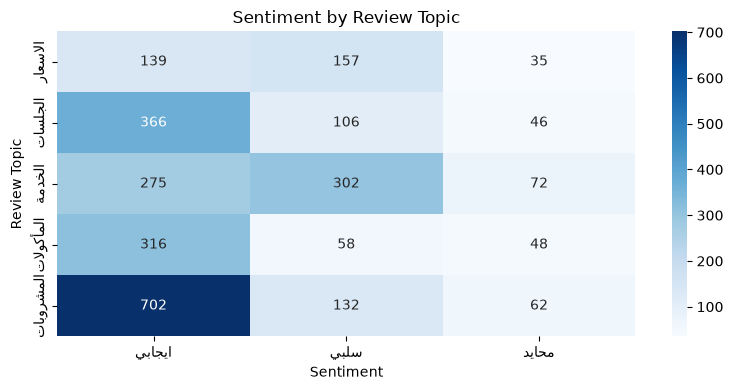

In [31]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

counts = pd.crosstab(df_clean["Attribute"], df_clean["Result"])
display(counts)

plt.figure(figsize=(8, 4))
ax = sns.heatmap(counts, annot=True, fmt="d", cmap="Blues")
ax.set(
    title="Sentiment by Review Topic",
    xlabel="Sentiment",
    ylabel="Review Topic",
)
plt.tight_layout()
plt.show()

In [32]:
pattern = (
    r";\s*(?:الخدمة|المشروبات|الجلسات|المأكولات|ال[اأ]سعار)"
    r"\s*;\s*(?:[اإ]يجابي|سلب[ييى]|محايد)\s*$"
)

has_embedded_labels = df_clean["Review"].str.contains(
    pattern, regex=True, na=False
)

print("Reviews with embedded labels:", has_embedded_labels.sum())
display(df_clean.loc[has_embedded_labels, ["Review", "Attribute", "Result"]].head(10))

Reviews with embedded labels: 465


,Review,Attribute,Result
11,تجربة غير موفقة في الكروسان الجبن عطاني الكروس...,المأكولات,سلبي
17,احببته، مكان يستحق الزيارة\n\n\nLoved it;الجل...,الجلسات,ايجابي
19,مكان جميل\n\n\nNice place;الجلسات;ايجابي,الجلسات,ايجابي
20,فرع جديد في موقع \n\n\nNew branch in good loc...,الجلسات,ايجابي
27,انا احب المكان رائع \n\n\nI love the spot so ...,الجلسات,ايجابي
28,أفضل مكان للتسكع مع الأصدقاء\n\n\nBest place ...,الجلسات,ايجابي
29,، جلساته مرتبة و ديكور مميز\n\n\nSo good;ال...,الجلسات,ايجابي
30,أجواء رائعة خصوصا في رمضان لقضاء بعض الوقت\n\...,الجلسات,ايجابي
31,مكان جميل لقضاء عطلة عمل قصيرة\n\n\nnice plac...,الجلسات,ايجابي
32,أحب خدمة السيارات لديهم\n\n\nLove the drive t...,الخدمة,ايجابي


In [33]:
df_model = df_clean.copy()

df_model["Review"] = (
    df_model["Review"].str.replace(pattern, "", regex=True).str.strip()
)

blank_reviews = df_model["Review"].eq("")
new_duplicates = df_model.loc[~blank_reviews].duplicated().sum()

print("Embedded labels remaining:",
      df_model["Review"].str.contains(pattern, regex=True, na=False).sum())
print("Empty reviews after cleaning:", blank_reviews.sum())
print("Duplicate rows after cleaning:", new_duplicates)

df_model = df_model.loc[~blank_reviews].drop_duplicates().reset_index(drop=True)
print("Final shape:", df_model.shape)

Embedded labels remaining: 0
Empty reviews after cleaning: 0
Duplicate rows after cleaning: 9
Final shape: (2807, 3)


In [34]:
repeated_reviews = df_model.loc[
    df_model["Review"].duplicated(keep=False),
    ["Review", "Attribute", "Result"],
].sort_values("Review")

print("Rows with repeated review text:", len(repeated_reviews))
print("Distinct repeated texts:", repeated_reviews["Review"].nunique())
display(repeated_reviews.head(10))

Rows with repeated review text: 22
Distinct repeated texts: 11


,Review,Attribute,Result
2019,الموقع تمام و التعامل تمام وسرعة الطلب,الخدمة,ايجابي
2044,الموقع تمام و التعامل تمام وسرعة الطلب,الخدمة,سلبي
36,تجربة الله ليست سيئة خدمة متوسطة\n\n\nGud expe...,الخدمة,ايجابي
463,تجربة الله ليست سيئة خدمة متوسطة\n\n\nGud expe...,الخدمة,محايد
359,جميل ولكن لدي تحفظ من ناحية الأسعار,الاسعار,سلبي
372,جميل ولكن لدي تحفظ من ناحية الأسعار,الاسعار,محايد
410,جميل لكن كعادة استاربوكس هنا اسعاره غالي,الاسعار,محايد
1178,جميل لكن كعادة استاربوكس هنا اسعاره غالي,الاسعار,سلبي
494,جميل موقع يحتاج اهتمام بالنظافة اكثر في الطاب...,الجلسات,سلبي
549,جميل موقع يحتاج اهتمام بالنظافة اكثر في الطاب...,الخدمة,سلبي


## 2. Detect outlier Scatterplot

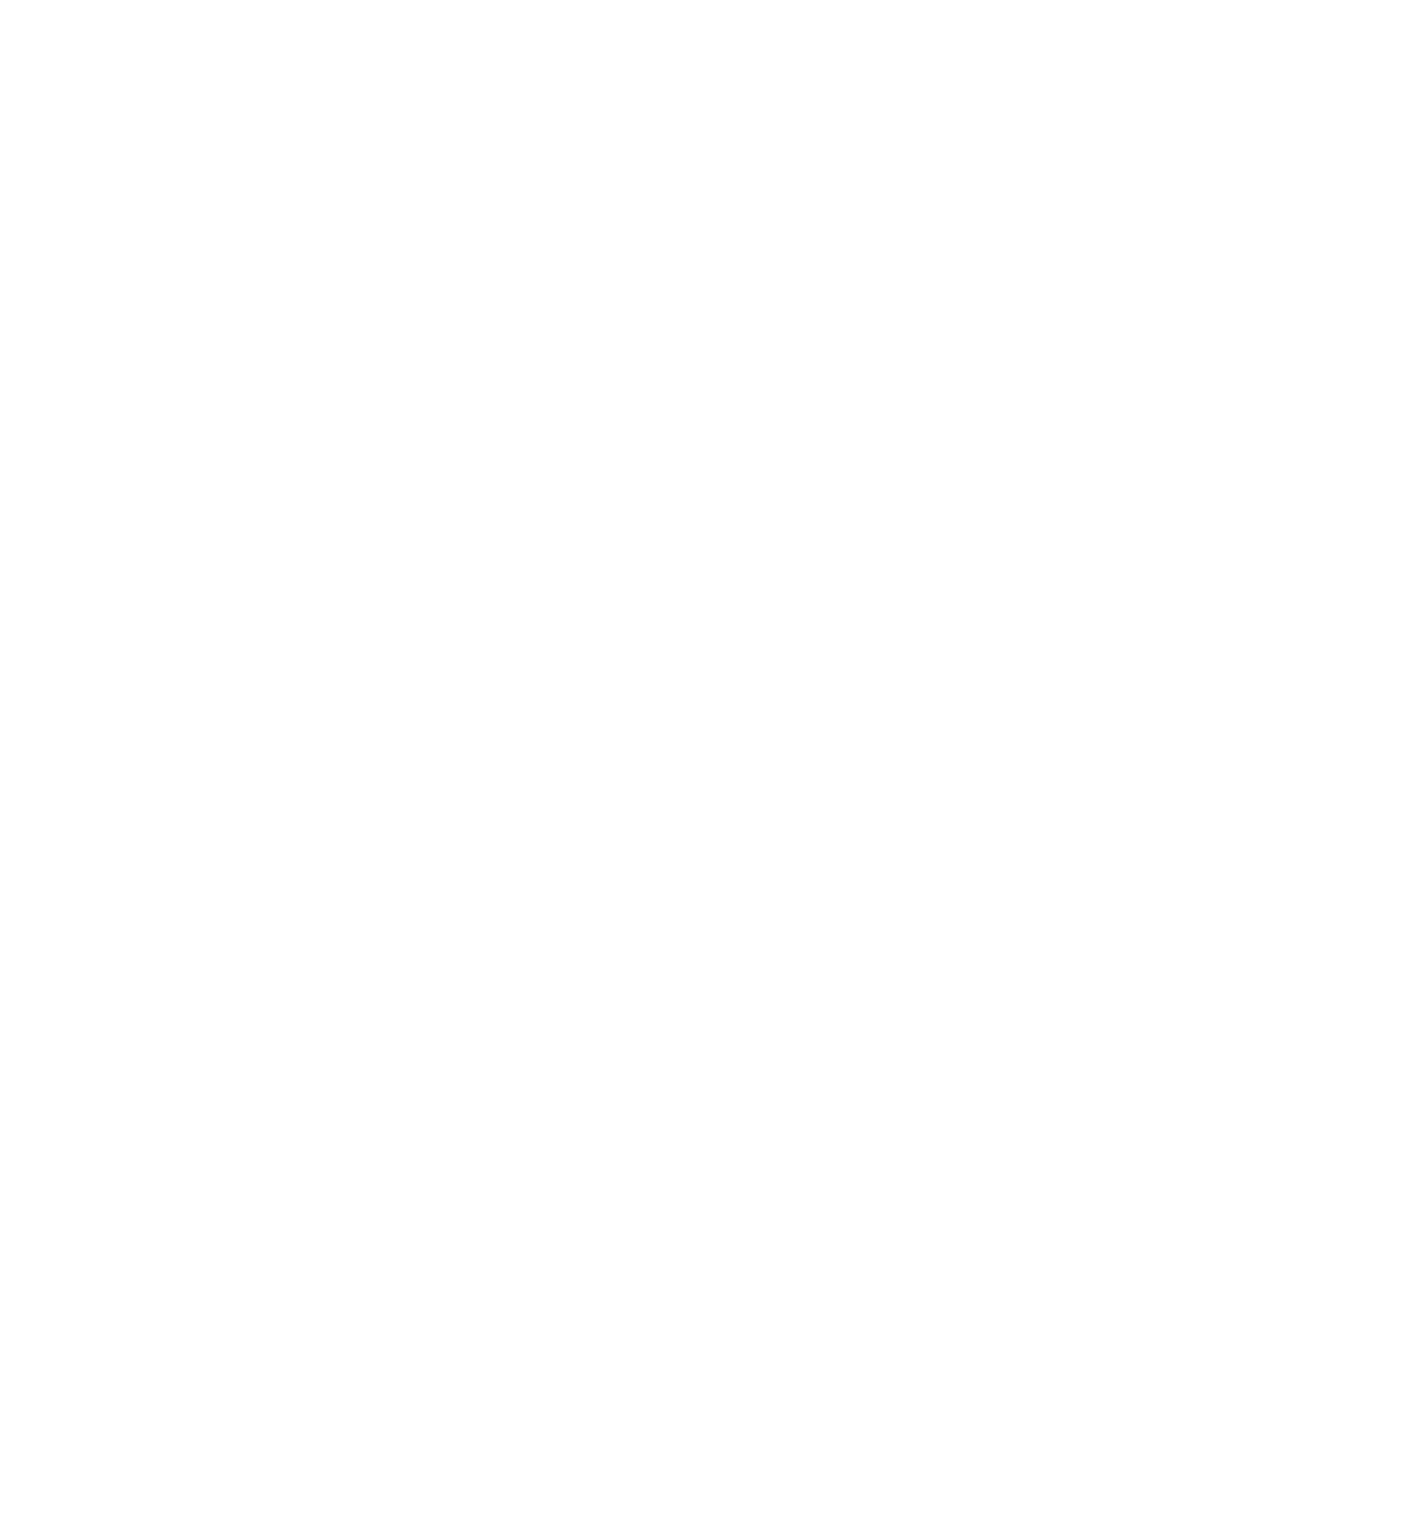

In [35]:
sensor_cols = [
    col for col in df.columns
    if col.startswith("sensor_") and df[col].nunique() > 1
]

fig, axes = plt.subplots(5, 3, figsize=(14, 15))
axes = axes.flatten()

for ax, col in zip(axes, sensor_cols):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(col)
    ax.set_xlabel("Reading")

for ax in axes[len(sensor_cols):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

C:\Users\engza\AppData\Local\Temp\ipykernel_8832\1952637998.py:16: UserWarning: Glyph 128077 (\N{THUMBS UP SIGN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\engza\AppData\Local\Temp\ipykernel_8832\1952637998.py:16: UserWarning: Glyph 128069 (\N{TONGUE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\engza\AppData\Local\Temp\ipykernel_8832\1952637998.py:16: UserWarning: Glyph 127801 (\N{ROSE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\engza\AppData\Local\Temp\ipykernel_8832\1952637998.py:16: UserWarning: Glyph 128076 (\N{OK HAND SIGN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\engza\AppData\Local\Temp\ipykernel_8832\1952637998.py:16: UserWarning: Glyph 9995 (\N{RAISED HAND}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\engza\AppData\Local\Temp\ipykernel_8832\1952637998.py:16: UserWarning: Glyph 128078 (\N{THUMBS DOWN SIGN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\

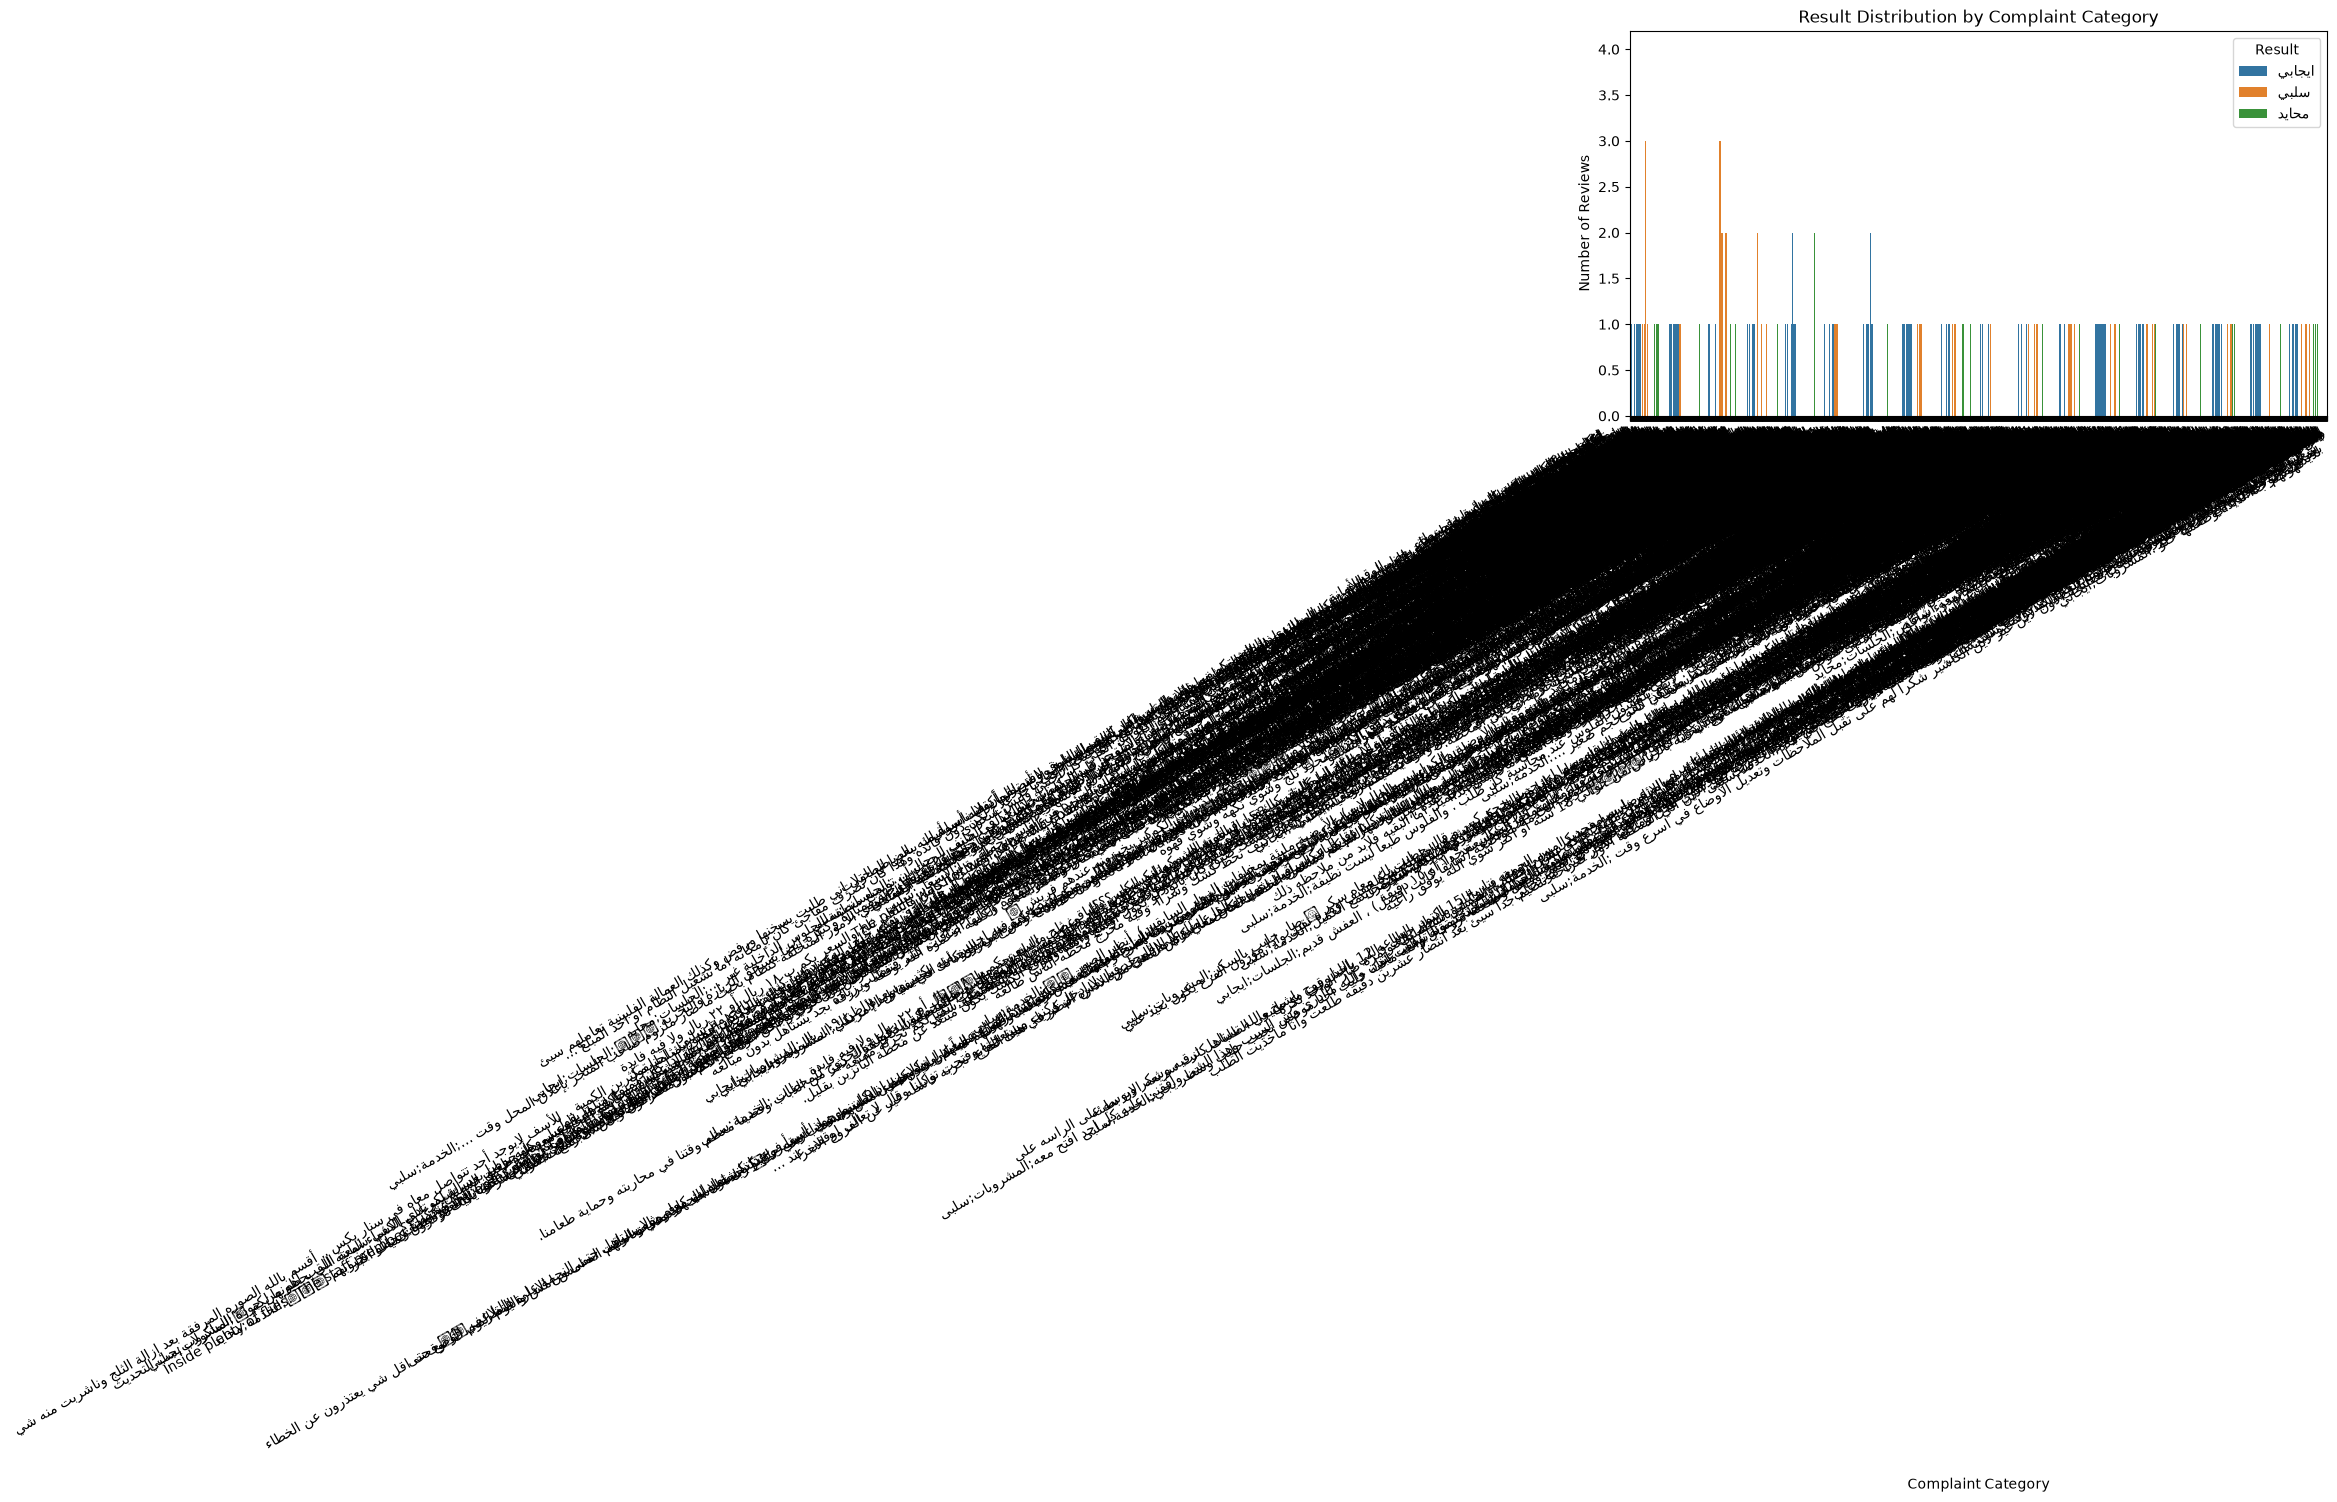

In [36]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Review",  # غيّريه لاسم عمود فئة الشكوى
    hue="Result",             # استخدمي "Result" إذا كان بحرف كبير
)

plt.title("Result Distribution by Complaint Category")
plt.xlabel("Complaint Category")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

# 4- Declare feature vector and target variable

In [37]:
from sklearn.model_selection import StratifiedGroupKFold

X = df_model["Review"]
y = df_model["Result"]

# 5- Split data into separate training and test set

In [38]:
# # split X and y into training and testing sets

# from sklearn.model_selection import train_test_split

# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 0)


In [39]:

splitter = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=42
)
train_idx, test_idx = next(splitter.split(X, y, groups=X))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print("Train rows:", len(X_train))
print("Test rows:", len(X_test))
print("Shared review texts:", len(set(X_train) & set(X_test)))

display(y_train.value_counts())
display(y_test.value_counts())

Train rows: 2245
Test rows: 562
Shared review texts: 0


Result
ايجابي    1435
سلبي       600
محايد      210
Name: count, dtype: int64

Result
ايجابي    359
سلبي      150
محايد      53
Name: count, dtype: int64

# 5- Models Training

In [40]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.pipeline import make_pipeline

logreg = make_pipeline(
    TfidfVectorizer(),
    LogisticRegression(max_iter=1000),
)

logreg.fit(X_train, y_train)
y_pred = logreg.predict(X_test)

print(classification_report(y_test, y_pred, digits=3, zero_division=0))

              precision    recall  f1-score   support

      ايجابي      0.786     0.953     0.861       359
        سلبي      0.721     0.587     0.647       150
       محايد      0.800     0.075     0.138        53

    accuracy                          0.772       562
   macro avg      0.769     0.538     0.549       562
weighted avg      0.770     0.772     0.736       562



In [41]:
# # train a logistic regression model on the training set
# from sklearn.linear_model import LogisticRegression   #only for classification


# # instantiate the model
# logreg = LogisticRegression(solver='liblinear', random_state=0)


# # fit the model
# logreg.fit(X_train, y_train)

# 6- Models Evaluations

## 1.Check accuracy score

## 2.Confusion matrix

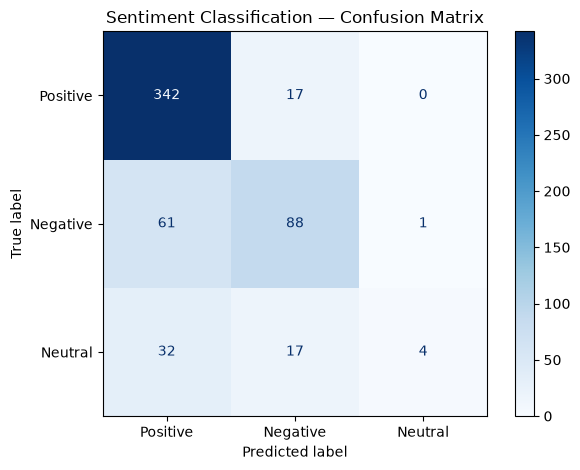

In [42]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=["ايجابي", "سلبي", "محايد"],
    display_labels=["Positive", "Negative", "Neutral"],
    cmap="Blues",
    values_format="d",
)

plt.title("Sentiment Classification — Confusion Matrix")
plt.tight_layout()
plt.show()

## 3.Classification metrices

In [43]:
from sklearn.metrics import classification_report

labels = ["ايجابي", "سلبي", "محايد"]

print(classification_report(
    y_test,
    y_pred,
    labels=labels,
    digits=3,
    zero_division=0,
))

              precision    recall  f1-score   support

      ايجابي      0.786     0.953     0.861       359
        سلبي      0.721     0.587     0.647       150
       محايد      0.800     0.075     0.138        53

    accuracy                          0.772       562
   macro avg      0.769     0.538     0.549       562
weighted avg      0.770     0.772     0.736       562



## 4.Precision

## 5.Recall

## 6.F1


## 7.Specificity


In [44]:
import pandas as pd
from sklearn.metrics import multilabel_confusion_matrix

matrices = multilabel_confusion_matrix(y_test, y_pred, labels=labels)
specificity_scores = []

for label, matrix in zip(labels, matrices):
    tn, fp, fn, tp = matrix.ravel()
    specificity = tn / (tn + fp) if tn + fp else float("nan")
    specificity_scores.append(specificity)

display(pd.DataFrame({
    "Class": labels,
    "Specificity": specificity_scores,
}).set_index("Class").round(3))

,Specificity
Class,
ايجابي,0.542
سلبي,0.917
محايد,0.998


## 8.  Adjusting the threshold level

In [45]:
import pandas as pd
from sklearn.metrics import multilabel_confusion_matrix

matrices = multilabel_confusion_matrix(y_test, y_pred, labels=labels)
specificity_scores = []

for label, matrix in zip(labels, matrices):
    tn, fp, fn, tp = matrix.ravel()
    specificity = tn / (tn + fp) if tn + fp else float("nan")
    specificity_scores.append(specificity)

display(pd.DataFrame({
    "Class": labels,
    "Specificity": specificity_scores,
}).set_index("Class").round(3))

,Specificity
Class,
ايجابي,0.542
سلبي,0.917
محايد,0.998


## 9.ROC - AUC

In [46]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
fit_idx, val_idx = next(cv.split(X_train, y_train, groups=X_train))

X_val = X_train.iloc[val_idx]
y_val = y_train.iloc[val_idx]

validation_model = clone(logreg)
validation_model.fit(X_train.iloc[fit_idx], y_train.iloc[fit_idx])

negative_col = list(validation_model.classes_).index("سلبي")
negative_probability = validation_model.predict_proba(X_val)[:, negative_col]

Validation ROC–AUC (Negative vs Rest): 0.885


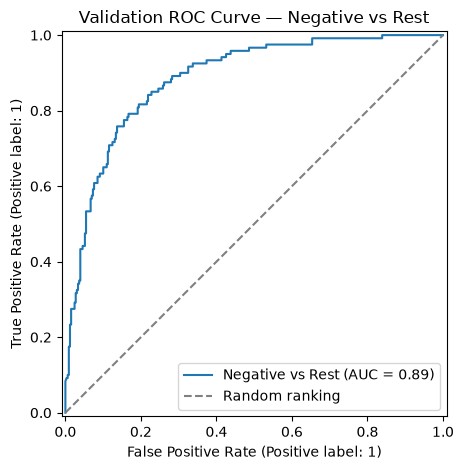

In [47]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay, roc_auc_score

y_val_negative = y_val == "سلبي"

auc = roc_auc_score(y_val_negative, negative_probability)
print(f"Validation ROC–AUC (Negative vs Rest): {auc:.3f}")

ax = RocCurveDisplay.from_predictions(
    y_val_negative,
    negative_probability,
    name="Negative vs Rest",
).ax_

ax.plot([0, 1], [0, 1], "--", color="gray", label="Random ranking")
ax.set_title("Validation ROC Curve — Negative vs Rest")
ax.legend()
plt.tight_layout()
plt.show()

## 10. k-Fold Cross Validation

## 11. Hyperparameter Optimization using GridSearch CV

In [48]:
import pandas as pd
from sklearn.metrics import classification_report
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

param_grid = {
    "tfidfvectorizer__ngram_range": [(1, 1), (1, 2)],
    "logisticregression__C": [0.1, 1, 10],
    "logisticregression__class_weight": [None, "balanced"],
}

grid_search = GridSearchCV(
    estimator=logreg,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
)

grid_search.fit(X_train, y_train, groups=X_train)

print("Best parameters:", grid_search.best_params_)
print(f"Best mean CV Macro F1: {grid_search.best_score_:.3f}")

best_model = grid_search.best_estimator_
y_pred_tuned = best_model.predict(X_test)

print("\nTest classification report")
print(classification_report(y_test, y_pred_tuned, digits=3, zero_division=0))

Best parameters: {'logisticregression__C': 1, 'logisticregression__class_weight': 'balanced', 'tfidfvectorizer__ngram_range': (1, 1)}
Best mean CV Macro F1: 0.660

Test classification report
              precision    recall  f1-score   support

      ايجابي      0.877     0.833     0.854       359
        سلبي      0.617     0.720     0.665       150
       محايد      0.457     0.396     0.424        53

    accuracy                          0.762       562
   macro avg      0.650     0.650     0.648       562
weighted avg      0.768     0.762     0.763       562



# 7- Save Models

# 8- Deploy Models